
### Sandbox Exercise 2: The Two-Site "Stiff" System (Advanced)

Background: Let's replicate the exact problem that causes differential equation solvers to crash when modeling cancer resistance networks. Consider a compound $B$ that has two independent proton binding sites $\(K_{a1}\)$ and $\(K_{a2}\)$). It can exist as $\(B^{2-}\)$, $\(HB^{-}\)$, or $H_{2}B$


Your Exercise Task:

Write down the complete 3-term Binding Polynomial (\(P_{B}\)) for this system using the macro pool definition:
\(\sum [B]=[B^{2-}]+[HB^{-}]+[H_{2}B]\)
Express your final polynomial strictly in terms of \([H^+]\), \(K_{a1}\), and \(K_{a2}\), choosing the completely unprotonated species \(B^{2-}\) as your foundational baseline reference.

Note: $\text{HB}^-$ exists in two forms depending on which binding cite is occupied: $[\text{HB}_\unicode{x2460}^-], [HB_\unicode{x2461}^-]$


In [1]:
import bionetgen
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import tellurium as te

from scipy.integrate import solve_ivp

$$
\begin{align}
{d \over dt}{[\text{B}^{2-}]}\ \  &= - k_{\text{on}_1} [\text{H}^{+}] [\text{B}^{2-}] + k_{\text{off}_1} [\text{HB}_\unicode{x2460}^{-}] 
                                 - k_{\text{on}_2} [\text{H}^{+}] [\text{B}^{2-}] + k_{\text{off}_2} [\text{HB}_\unicode{x2461}^{-}] \\
{d \over dt}{[\text{HB}_\unicode{x2460}^{-}]} & =\ \   k_{\text{on}_1} [\text{H}^{+}] [\text{B}^{2-}] 
                                                - k_{\text{off}_1} [\text{HB}_\unicode{x2460}^{-}] 
                                                - k_{\text{on}_2} [\text{HB}_\unicode{x2460}^{-}] [\text{H}^+] 
                                                + k_{\text{off}_2} [\text{H}_2\text{B}] \\
{d \over dt}{[\text{HB}_\unicode{x2461}^{-}]} & =\   k_{\text{on}_2} [\text{H}^{+}] [\text{B}^{2-}] 
                                                - k_{\text{off}_2} [\text{HB}_\unicode{x2461}^{-}]
                                                - k_{\text{on}_1} [\text{HB}_\unicode{x2461}^{-}] [\text{H}^+] 
                                                + k_{\text{off}_1} [\text{H}_2\text{B}] \\
{d \over dt}{[\text{H}_2\text{B}]} & = \ \  k_{\text{on}_2} [\text{HB}_\unicode{x2460}^-] [\text{H}^+] 
                                     + k_{\text{on}_1} [\text{HB}_\unicode{x2461}^-] [\text{H}^+]
                                     - k_{\text{off}_1} [\text{H}_2\text{B}] 
                                     - k_{\text{off}_2} [\text{H}_2\text{B}] \\                                               
\end{align}                                 
$$

In [ ]:
model = bionetgen.bngmodel("two_site_stiff.bngl")

In [ ]:
print(model)

In [ ]:
model.setup_simulator()

In [ ]:
model = bionetgen.bngmodel("two_site_stiff.bngl")
rr = model.setup_simulator()

In [ ]:
for obs in model.observables:
    print(obs)

In [ ]:
sbml_xml_data = rr.getSBML() 

In [ ]:
antimony_code = te.sbmlToAntimony(sbml_xml_data)

In [ ]:
print(antimony_code)

### Reactions

##### Rule 1:Protonation of Site 1 (Driven by background $\text{H}^+$ ions pool)
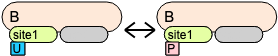

BNGL code: ```B(site1~U) <-> B(site1~P) k_on1*H_ions, k_off1```

##### Rule 2: Protonation of Site 2 (Independent of Site 1)
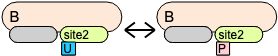

BNGL code: ```B(site2~U) ↔ B(site2~P) k_on2*H_ions, k_off2```

In [ ]:
def f(t,X, H=1.e-6, k_on1=1.0e8, k_on2=1.0e6, k_off1=1.0e2, k_off2=1.0e4):
    B,HB_1,HB_2,H2B = X
    dB    = -k_on1*H*B - k_on2*H*B + k_off1*HB_1 + k_off2*HB_2
    dHB_1 =  k_on1*H*B - k_off1*HB_1 - k_on2*HB_1*H + k_off2*H2B 
    dHB_2 = k_on2*H*B - k_off2*HB_2 - k_on1*HB_2*H + k_off1*H2B
    dH2B = k_on2*HB_1*H + k_on1*HB_2*H - k_off1*H2B - k_off2*H2B

    return( [dB,dHB_1,dHB_2,dH2B] )

In [ ]:
Ka2 = 1.0e4/1.0e6
Ka2

In [ ]:
Ka1 = 1.0e2/1.0e8
Ka1

In [ ]:
rr['B_total']

In [ ]:
tEnd = 0.05
soln = solve_ivp(f, [0,tEnd], [rr['B_total'], 0,0,0], method='LSODA', dense_output=True)

In [ ]:
soln

In [ ]:
tEnd*100

In [ ]:
t = np.linspace(0, tEnd, 1000 + 1)
t[0:3]

In [ ]:
B, HB_1, HB_2, H2B = soln.sol(t)

In [ ]:
plt.plot(t, B, 'b')
plt.plot(t, HB_1, 'g')
plt.plot(t, HB_2, 'darkgreen')
plt.plot(t, H2B, 'red')
plt.show()

In [ ]:
B[-1] + HB_1[-1] + HB_2[-1] + H2B[-1]

In [ ]:
HB_2[-1]

In [ ]:
H = 1.e-6

In [ ]:
print(f"{B[-1]*H/HB_1[-1]:.2e}")
print(Ka1)

In [ ]:
print(f"{B[-1]*H/HB_2[-1]:.2f}")
print(Ka2)

In [ ]:
print(f"{B[-1]*H**2/(Ka2*Ka1):.2e}")
print(f"{H2B[-1]:.2e}")

In [ ]:
Sum_B = B[-1] + HB_1[-1] + HB_2[-1] + H2B[-1] 
print(f"{Sum_B:.4f}")

In [ ]:
P = 1 + (1/Ka1 + 1/Ka2)*H + (1/(Ka1*Ka2))*H**2
print(f"{B[-1]*P:.4f}")

In [ ]:
import bionetgen
import matplotlib.pyplot as plt

In [6]:
# 1. Run the rule-based simulation file
result = bionetgen.run("two_site_stiff.bngl")

In [7]:
# 2. Extract the time-course data matrix from the simulation
r = result[0]

In [8]:
r.dtype.names

('time',
 'Total_B',
 'Active_Bare_Ion',
 'First_Protonated',
 'Second_Protonated',
 'Fully_Protonated')

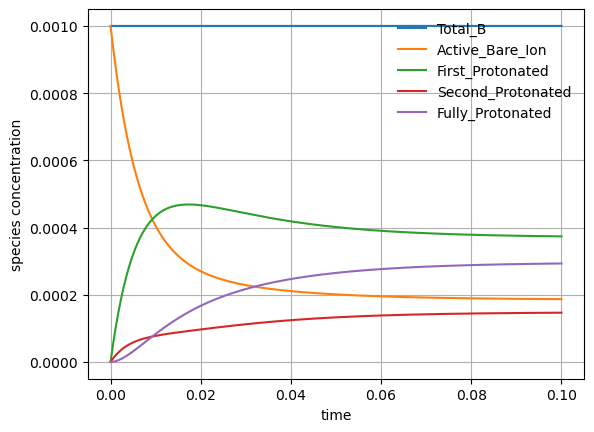

In [10]:
for name in r.dtype.names:
    if name != "time":
        plt.plot(r['time'], r[name], label=name)
plt.xlabel("time")
plt.ylabel("species concentration")
plt.grid()
_ = plt.legend(frameon=False)

In [ ]:
r['Active_Bare_Ion'][-1] + r['First_Protonated'][-1] + r['Second_Protonated'][-1] + r['Fully_Protonated'][-1]

In [ ]:
r.param

In [ ]:
HB = r['First_Protonated'][-1] +  r['Second_Protonated'][-1] 
HB

In [ ]:
B = r['Active_Bare_Ion'][-1]
B

In [ ]:
Hp = 1.e-6

In [ ]:
B*Hp/HB

In [ ]:
model = bionetgen.bngmodel("two_site_stiff.bngl")

In [ ]:
print(model)

In [ ]:
print(model.parameters)

In [ ]:
model.parameters['k_off1']

In [ ]:
model.parameters['k_off2'] = 1.e4

In [ ]:
print(model)